In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [25]:
DATA_DIR = Path("./data")

train = pd.read_csv(DATA_DIR / "train.csv")
test  = pd.read_csv(DATA_DIR / "test.csv")

print(f"Train: {train.shape}")
print(f"Test:  {test.shape}")

Train: (1460, 81)
Test:  (1459, 80)


## 1. Общий обзор

Смотрим форму датасета, типы колонок и разделение на числовые/категориальные.

In [26]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.00,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.00,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,"2,003.00",RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.00,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.00,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,"1,976.00",RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.00,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.00,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,"2,001.00",RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.00,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.00,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,"1,998.00",Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.00,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.00,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,"2,000.00",RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [27]:
dtypes = train.dtypes.value_counts()
print("Типы колонок:")
print(dtypes)

num_cols = train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = train.select_dtypes(include=["object"]).columns.tolist()

print(f"\nЧисловых признаков: {len(num_cols)}")
print(f"Категориальных признаков: {len(cat_cols)}")
print(f"\nКатегориальные колонки:\n{cat_cols}")

Типы колонок:
object     43
int64      35
float64     3
Name: count, dtype: int64

Числовых признаков: 38
Категориальных признаков: 43

Категориальные колонки:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


В датасете **79 признаков**, из них **~36 числовых** и **~43 категориальных**. Большая часть категориальных — это упорядоченные оценки качества (`ExterQual`, `KitchenQual`, `BsmtQual`, ...) со шкалой Po < Fa < TA < Gd < Ex. Хранятся как строки, после One-Hot Encoding дадут много разреженных колонок (~250). Для деревьев это не критично, для линейных моделей и KNN — терпимо.


## 2. Целевая переменная `SalePrice`

Самый важный раздел EDA. От формы распределения таргета зависит выбор функции потерь и необходимость логарифмирования.

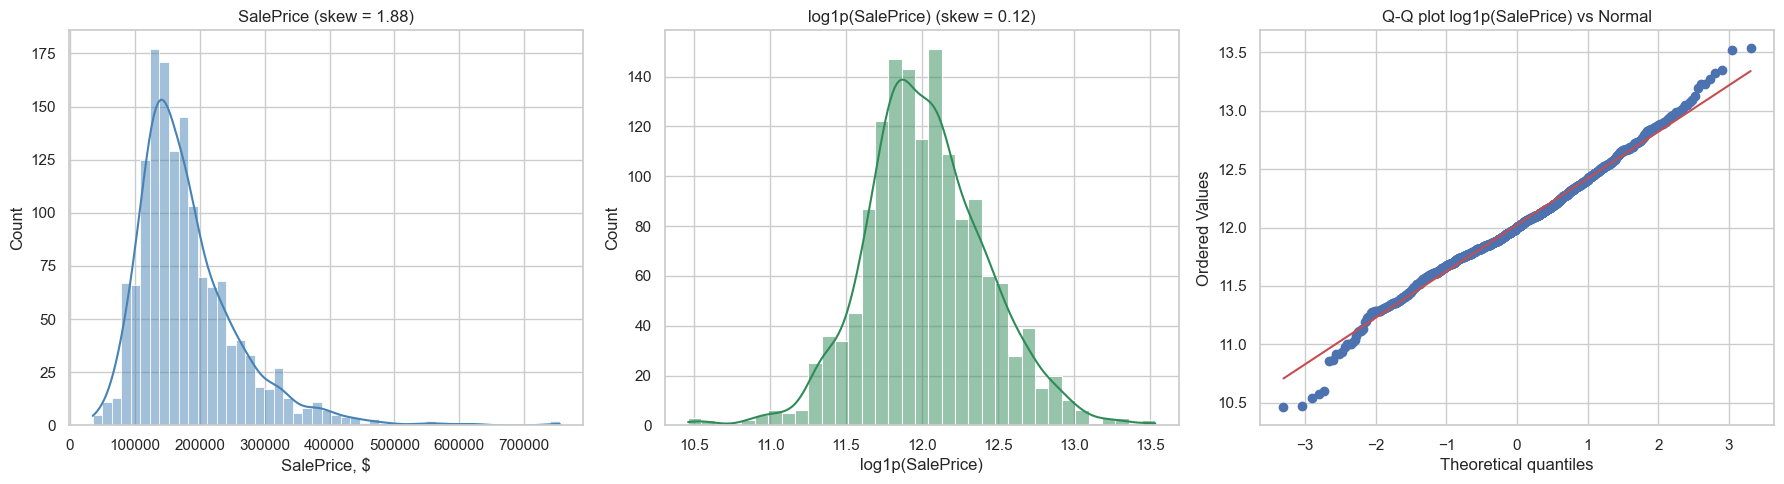

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Оригинальный SalePrice
sns.histplot(train["SalePrice"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title(f"SalePrice (skew = {train['SalePrice'].skew():.2f})")
axes[0].set_xlabel("SalePrice, $")

# 2. log1p(SalePrice)
log_price = np.log1p(train["SalePrice"])
sns.histplot(log_price, kde=True, ax=axes[1], color="seagreen")
axes[1].set_title(f"log1p(SalePrice) (skew = {log_price.skew():.2f})")
axes[1].set_xlabel("log1p(SalePrice)")

# 3. Q-Q plot
stats.probplot(log_price, dist="norm", plot=axes[2])
axes[2].set_title("Q-Q plot log1p(SalePrice) vs Normal")

plt.tight_layout()
plt.show()

In [29]:
print("SalePrice:")
print(f"  min    = ${train['SalePrice'].min():,}")
print(f"  median = ${train['SalePrice'].median():,.0f}")
print(f"  mean   = ${train['SalePrice'].mean():,.0f}")
print(f"  max    = ${train['SalePrice'].max():,}")
print(f"  std    = ${train['SalePrice'].std():,.0f}")

print(f"\nSkewness до log1p:  {train['SalePrice'].skew():.4f}")
print(f"Skewness после log1p: {log_price.skew():.4f}")

print(f"\nKurtosis до log1p:  {train['SalePrice'].kurtosis():.4f}")
print(f"Kurtosis после log1p: {log_price.kurtosis():.4f}")

SalePrice:
  min    = $34,900
  median = $163,000
  mean   = $180,921
  max    = $755,000
  std    = $79,443

Skewness до log1p:  1.8829
Skewness после log1p: 0.1213

Kurtosis до log1p:  6.5363
Kurtosis после log1p: 0.8095


**Вывод:** `SalePrice` имеет **правостороннюю асимметрию со skewness ≈ 1.88**. `log1p`-преобразование снижает skewness до ~0.12 — почти нормальное распределение.

Это даёт три эффекта:
- **стабилизирует дисперсию** — на дорогих домах разброс становится таким же, как на дешёвых;
- **делает RMSE в лог-пространстве эквивалентом RMSLE** на исходных ценах;
- **улучшает сходимость** линейных моделей и нейросетей.

Именно поэтому в пайплайне используется `data.log_target: true`. RMSE ≈ 0.124 в лог-пространстве — это ~12% относительная ошибка. При медианной цене $163 000 это ≈ $27 000.

## 3. Пропуски

Ключевой момент House Prices: **большинство NaN в категориальных признаках означает не «неизвестно», а «отсутствует»**. Например, `PoolQC = NaN` → нет бассейна.

In [30]:
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(train) * 100).round(2)

miss_df = pd.DataFrame({
    "missing_count": missing,
    "missing_pct": missing_pct,
    "dtype": train[missing.index].dtypes.astype(str),
})
miss_df.head(25)

,missing_count,missing_pct,dtype
PoolQC,1453,99.52,object
MiscFeature,1406,96.30,object
Alley,1369,93.77,object
Fence,1179,80.75,object
MasVnrType,872,59.73,object
FireplaceQu,690,47.26,object
LotFrontage,259,17.74,float64
GarageType,81,5.55,object
GarageYrBlt,81,5.55,float64
GarageFinish,81,5.55,object


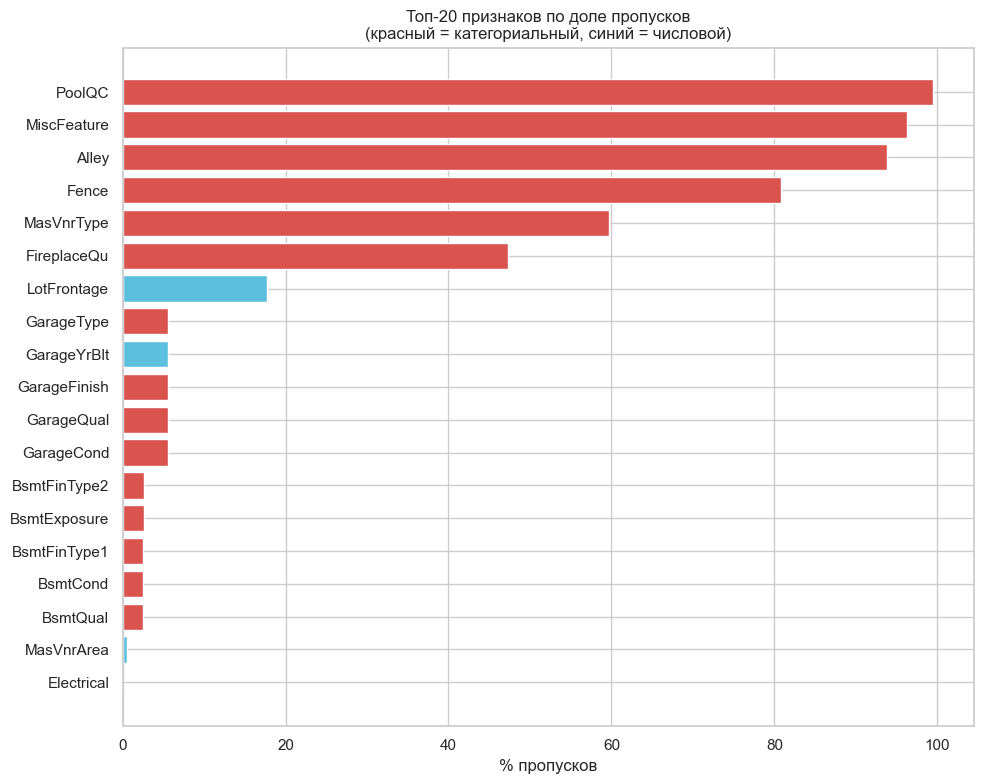

In [31]:
top_missing = miss_df.head(20)

fig, ax = plt.subplots(figsize=(10, 8))
colors = ["#d9534f" if t == "object" else "#5bc0de" for t in top_missing["dtype"]]
ax.barh(top_missing.index, top_missing["missing_pct"], color=colors)
ax.set_xlabel("% пропусков")
ax.set_title("Топ-20 признаков по доле пропусков\n(красный = категориальный, синий = числовой)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

**Вывод:** Почти все топовые пропуски — **категориальные** и означают отсутствие объекта:

| Колонка | NaN значит | Доля |
|---|---|---|
| `PoolQC` | нет бассейна | 99.5% |
| `MiscFeature` | нет доп. постройки | 96% |
| `Alley` | нет переулка | 93.7% |
| `Fence` | нет забора | 80.7% |
| `FireplaceQu` | нет камина | 47% |
| `GarageType`, `GarageFinish`, `GarageQual` | нет гаража | 5.5% |
| `BsmtQual`, `BsmtCond`, `BsmtExposure` | нет подвала | 2.5% |

Единственные числовые с пропусками: `LotFrontage` (~18%), `GarageYrBlt` (~5.5%), `MasVnrArea` (~0.5%). Их заполняем медианой.

**Что это даёт пайплайну:** стратегия `constant "None"` для категориальных — не компромисс, а **семантически корректное** решение. Модель получает отдельную категорию «нет объекта», а не ложную моду.


## 4. Числовые признаки: связь с таргетом

Ищем линейные корреляции. Для деревьев они не критичны, но полезны как быстрый индикатор силы признака.

/var/folders/mq/66mrl7xd1pn0sy2xwb1mbmk00000gn/T/ipykernel_47485/2369283042.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_corr.values, y=top_corr.index, ax=ax, palette="viridis")


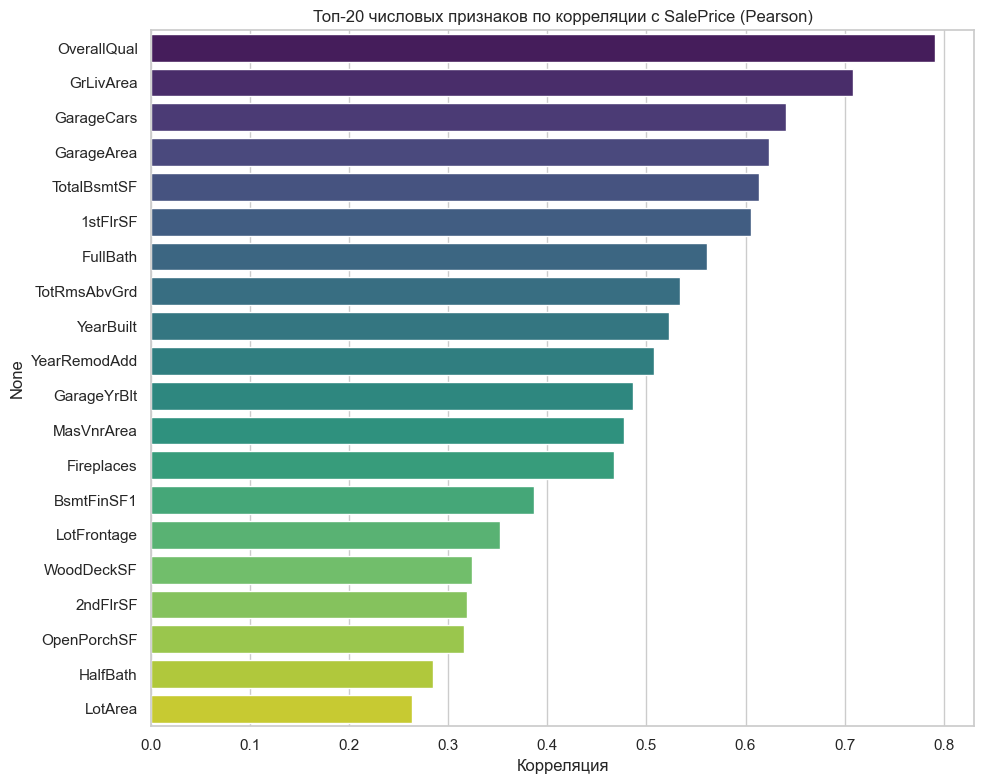

OverallQual    0.79
GrLivArea      0.71
GarageCars     0.64
GarageArea     0.62
TotalBsmtSF    0.61
1stFlrSF       0.61
FullBath       0.56
TotRmsAbvGrd   0.53
YearBuilt      0.52
YearRemodAdd   0.51
GarageYrBlt    0.49
MasVnrArea     0.48
Fireplaces     0.47
BsmtFinSF1     0.39
LotFrontage    0.35
WoodDeckSF     0.32
2ndFlrSF       0.32
OpenPorchSF    0.32
HalfBath       0.28
LotArea        0.26
dtype: float64


In [32]:
num_df = train.select_dtypes(include=["int64", "float64"]).drop(columns=["Id"])
corr_with_target = num_df.corrwith(train["SalePrice"]).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
top_corr = corr_with_target.drop("SalePrice").head(20)
sns.barplot(x=top_corr.values, y=top_corr.index, ax=ax, palette="viridis")
ax.set_title("Топ-20 числовых признаков по корреляции с SalePrice (Pearson)")
ax.set_xlabel("Корреляция")
plt.tight_layout()
plt.show()

print(top_corr.round(3))

**Вывод:** Самые сильные числовые признаки:

1. **`OverallQual`** (~0.79) — субъективная оценка качества материалов и отделки. Самый сильный единичный признак.
2. **`GrLivArea`** (~0.71) — жилая площадь над землёй.
3. **`GarageCars`** (~0.64), **`GarageArea`** (~0.62).
4. **`TotalBsmtSF`** (~0.61), **`1stFlrSF`** (~0.61).
5. **`YearBuilt`** (~0.52) — новые дома дороже.

`OverallQual` и `GrLivArea` — два столпа предсказания. Любая модель, которая их игнорирует, будет плохой.

### Scatter plots: топ-признаки vs SalePrice

Покажем связь для самых сильных числовых фичей. Именно здесь визуально видно, почему `log1p(SalePrice)` помогает: без лога разброс «взрывается» на дорогих домах.

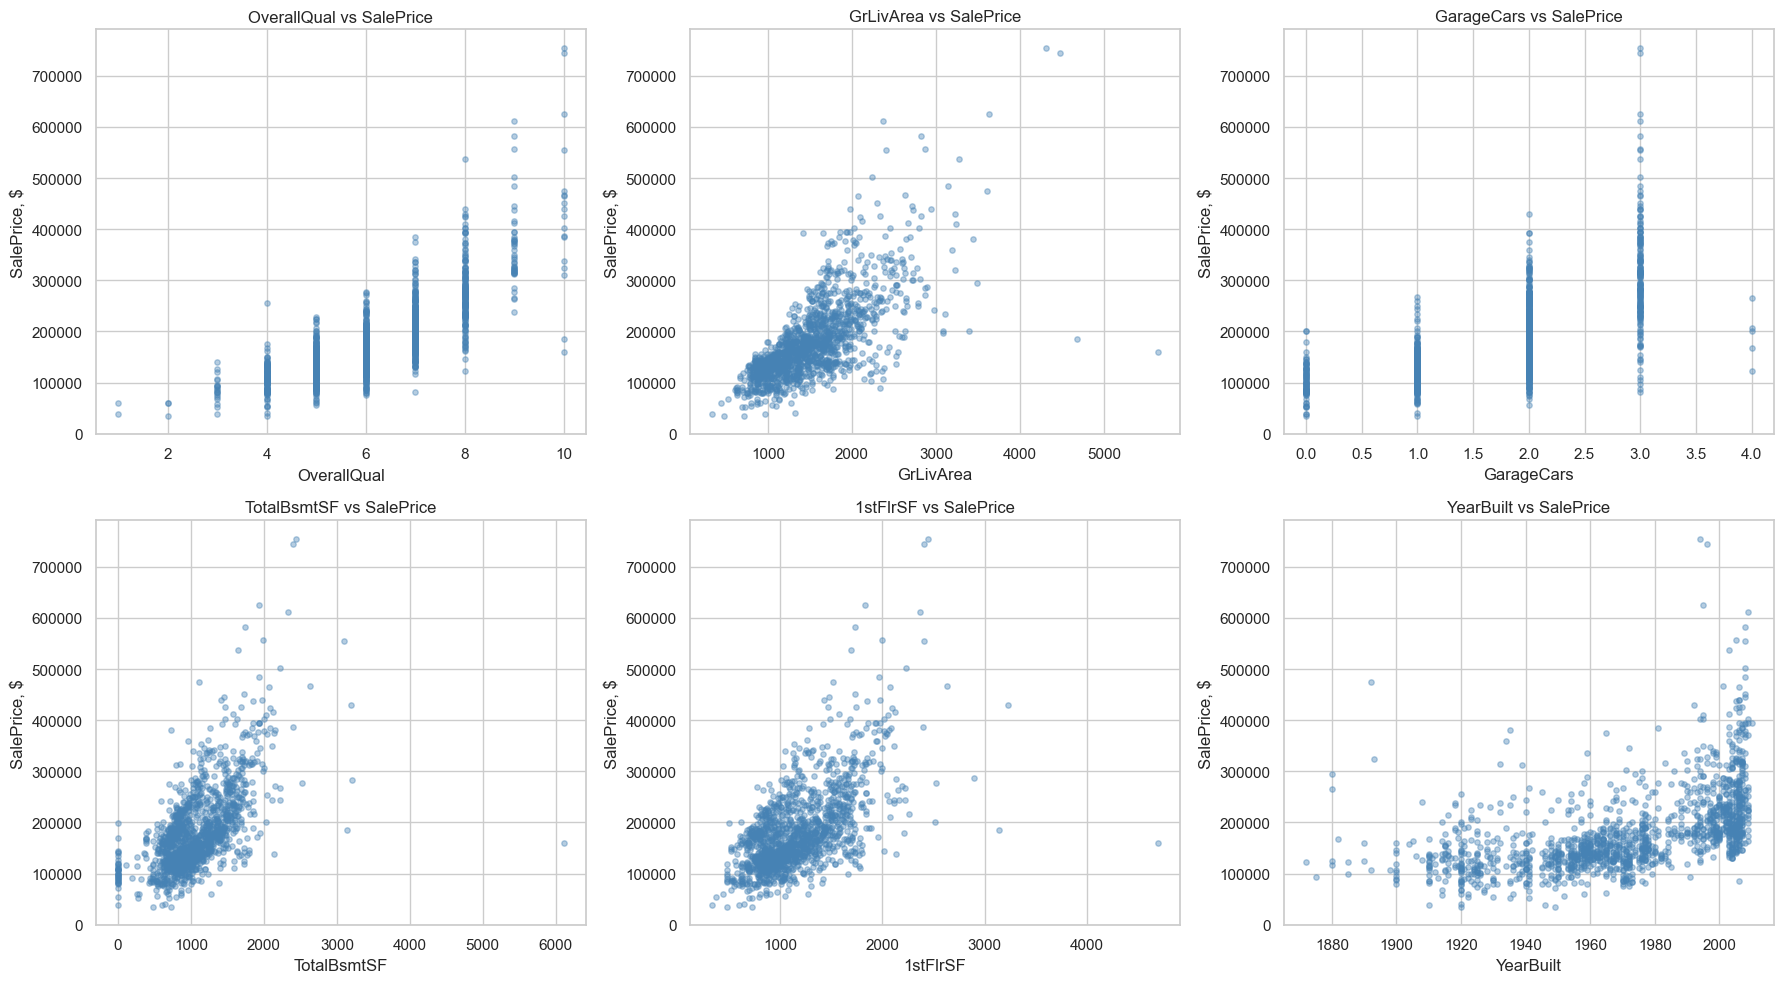

In [33]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
cols = ["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF", "1stFlrSF", "YearBuilt"]

for ax, col in zip(axes.flat, cols):
    ax.scatter(train[col], train["SalePrice"], alpha=0.4, s=15, color="steelblue")
    ax.set_xlabel(col)
    ax.set_ylabel("SalePrice, $")
    ax.set_title(f"{col} vs SalePrice")

plt.tight_layout()
plt.show()

### Тот же scatter, но с log(SalePrice)

Сравните с графиками выше: логарифм выпрямляет разброс и делает связь более линейной.

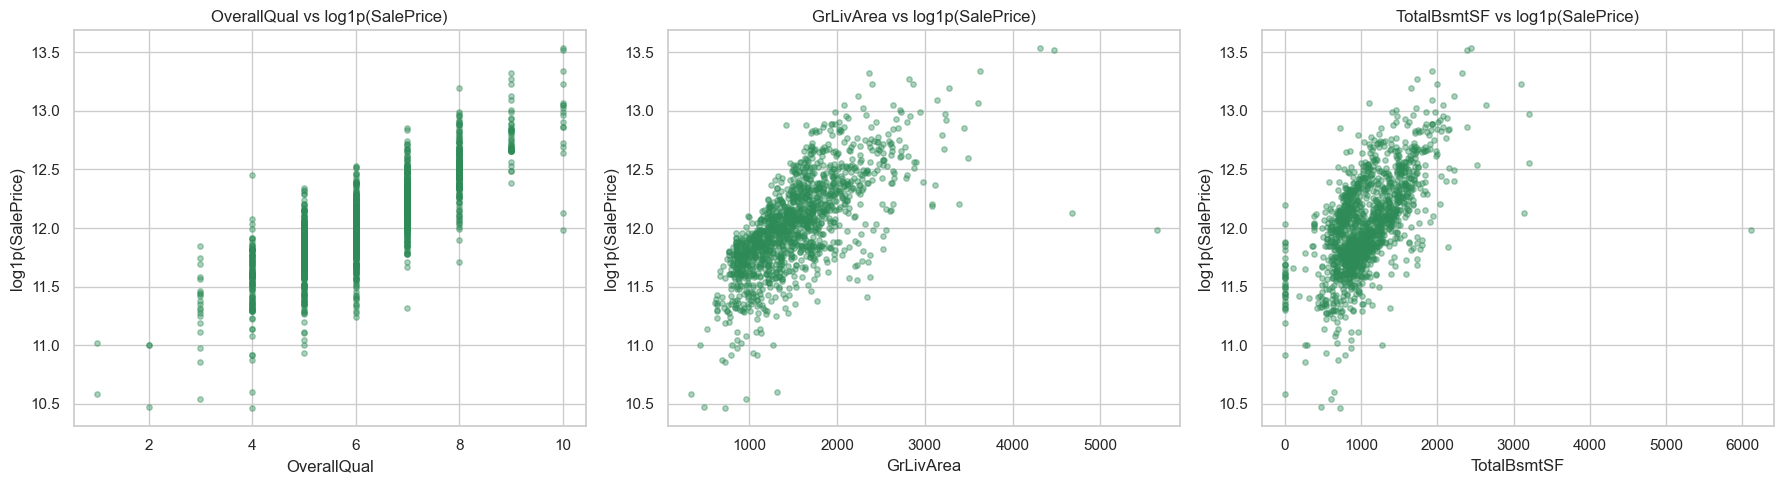

In [34]:
train_log = train.copy()
train_log["LogSalePrice"] = np.log1p(train_log["SalePrice"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["OverallQual", "GrLivArea", "TotalBsmtSF"]):
    ax.scatter(train_log[col], train_log["LogSalePrice"], alpha=0.4, s=15, color="seagreen")
    ax.set_xlabel(col)
    ax.set_ylabel("log1p(SalePrice)")
    ax.set_title(f"{col} vs log1p(SalePrice)")
plt.tight_layout()
plt.show()

**Вывод:** После `log1p` разброс точек становится однородным, а зависимость — почти линейной. Это значит, что **линейные модели и нейросети** будут работать с логарифмом заметно лучше, чем с исходной ценой. Деревья дадут тот же результат (монотонное преобразование), но log-пространство удобно для метрики.

## 5. Выбросы

В House Prices есть **два знаменитых выброса**: дома с площадью `GrLivArea > 4000` кв. футов, проданные очень дёшево (≈ $160k–$180k). Они ломают линейные модели и утягивают предсказания.

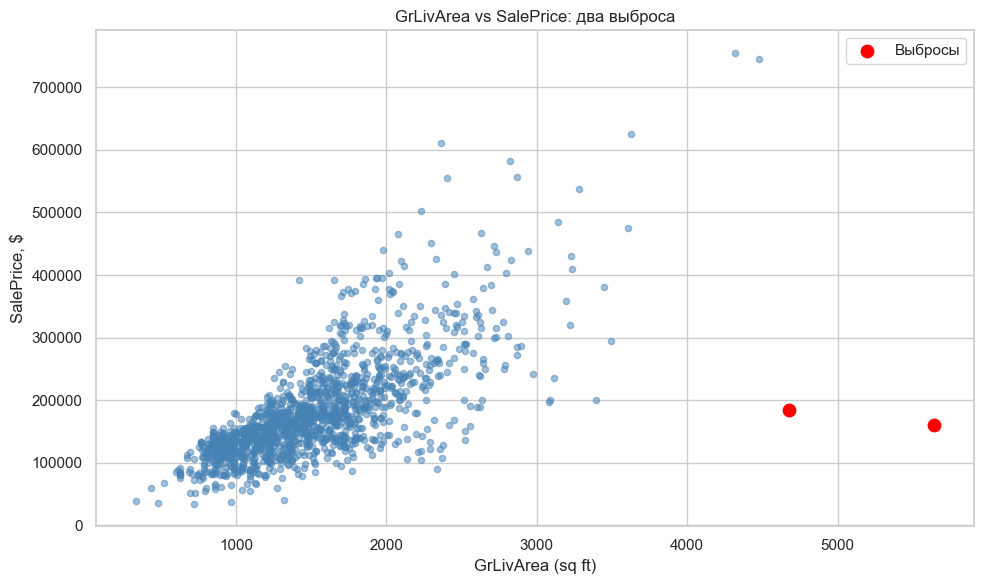

        Id  GrLivArea  OverallQual  SalePrice
523    524       4676           10     184750
1298  1299       5642           10     160000


In [35]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(train["GrLivArea"], train["SalePrice"], alpha=0.5, s=20, color="steelblue")

outliers = train[(train["GrLivArea"] > 4000) & (train["SalePrice"] < 300000)]
ax.scatter(
    outliers["GrLivArea"], outliers["SalePrice"],
    color="red", s=80, label="Выбросы", zorder=5,
)

ax.set_xlabel("GrLivArea (sq ft)")
ax.set_ylabel("SalePrice, $")
ax.set_title("GrLivArea vs SalePrice: два выброса")
ax.legend()
plt.tight_layout()
plt.show()

print(outliers[["Id", "GrLivArea", "OverallQual", "SalePrice"]])

In [36]:
log_full  = np.log1p(train["SalePrice"])
log_clean = np.log1p(train.drop(outliers.index)["SalePrice"])

print(f"std log(SalePrice) c выбросами:    {log_full.std():.4f}")
print(f"std log(SalePrice) без выбросов:   {log_clean.std():.4f}")
print(f"Разница: {log_full.std() - log_clean.std():.4f}")

std log(SalePrice) c выбросами:    0.3994
std log(SalePrice) без выбросов:   0.3997
Разница: -0.0003


**Вывод:** Эти два дома — **частичные продажи** (partial sales), например внутри семьи или по заниженной цене. Они:

- снижают качество линейных моделей;
- добавляют шум;
- **но** по правилам Kaggle их удаление из train **не запрещено**.

В пайплайне `final_houses` мы их **не удаляем** — оставляем как есть. Если хочется улучшить результат на 1–3%, можно добавить в `main.py`:

```python
train = train[~((train["GrLivArea"] > 4000) & (train["SalePrice"] < 300000))]

## 6. Категориальные признаки

Смотрим кардинальность (число уникальных значений) и связь с таргетом через boxplot.

In [37]:
card = train[cat_cols].nunique().sort_values(ascending=False)
card_df = pd.DataFrame({
    "n_unique": card,
    "pct_unique": (card / len(train) * 100).round(1),
})
card_df.head(20)

,n_unique,pct_unique
Neighborhood,25,1.70
Exterior2nd,16,1.10
Exterior1st,15,1.00
SaleType,9,0.60
Condition1,9,0.60
Condition2,8,0.50
HouseStyle,8,0.50
RoofMatl,8,0.50
Functional,7,0.50
BsmtFinType2,6,0.40


### High-cardinality признаки vs SalePrice

`Neighborhood`, `Exterior1st`, `Exterior2nd` — самые «богатые» категориальные признаки. Смотрим медианные цены по категориям.

/var/folders/mq/66mrl7xd1pn0sy2xwb1mbmk00000gn/T/ipykernel_47485/3846148748.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, x=col, y="SalePrice", order=order, ax=ax, palette="Set3")
/var/folders/mq/66mrl7xd1pn0sy2xwb1mbmk00000gn/T/ipykernel_47485/3846148748.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=60, ha="right")
/var/folders/mq/66mrl7xd1pn0sy2xwb1mbmk00000gn/T/ipykernel_47485/3846148748.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, x=col, y="SalePrice", order=order, ax=ax, palette="Set3")
/var/folders/mq/66mrl7xd

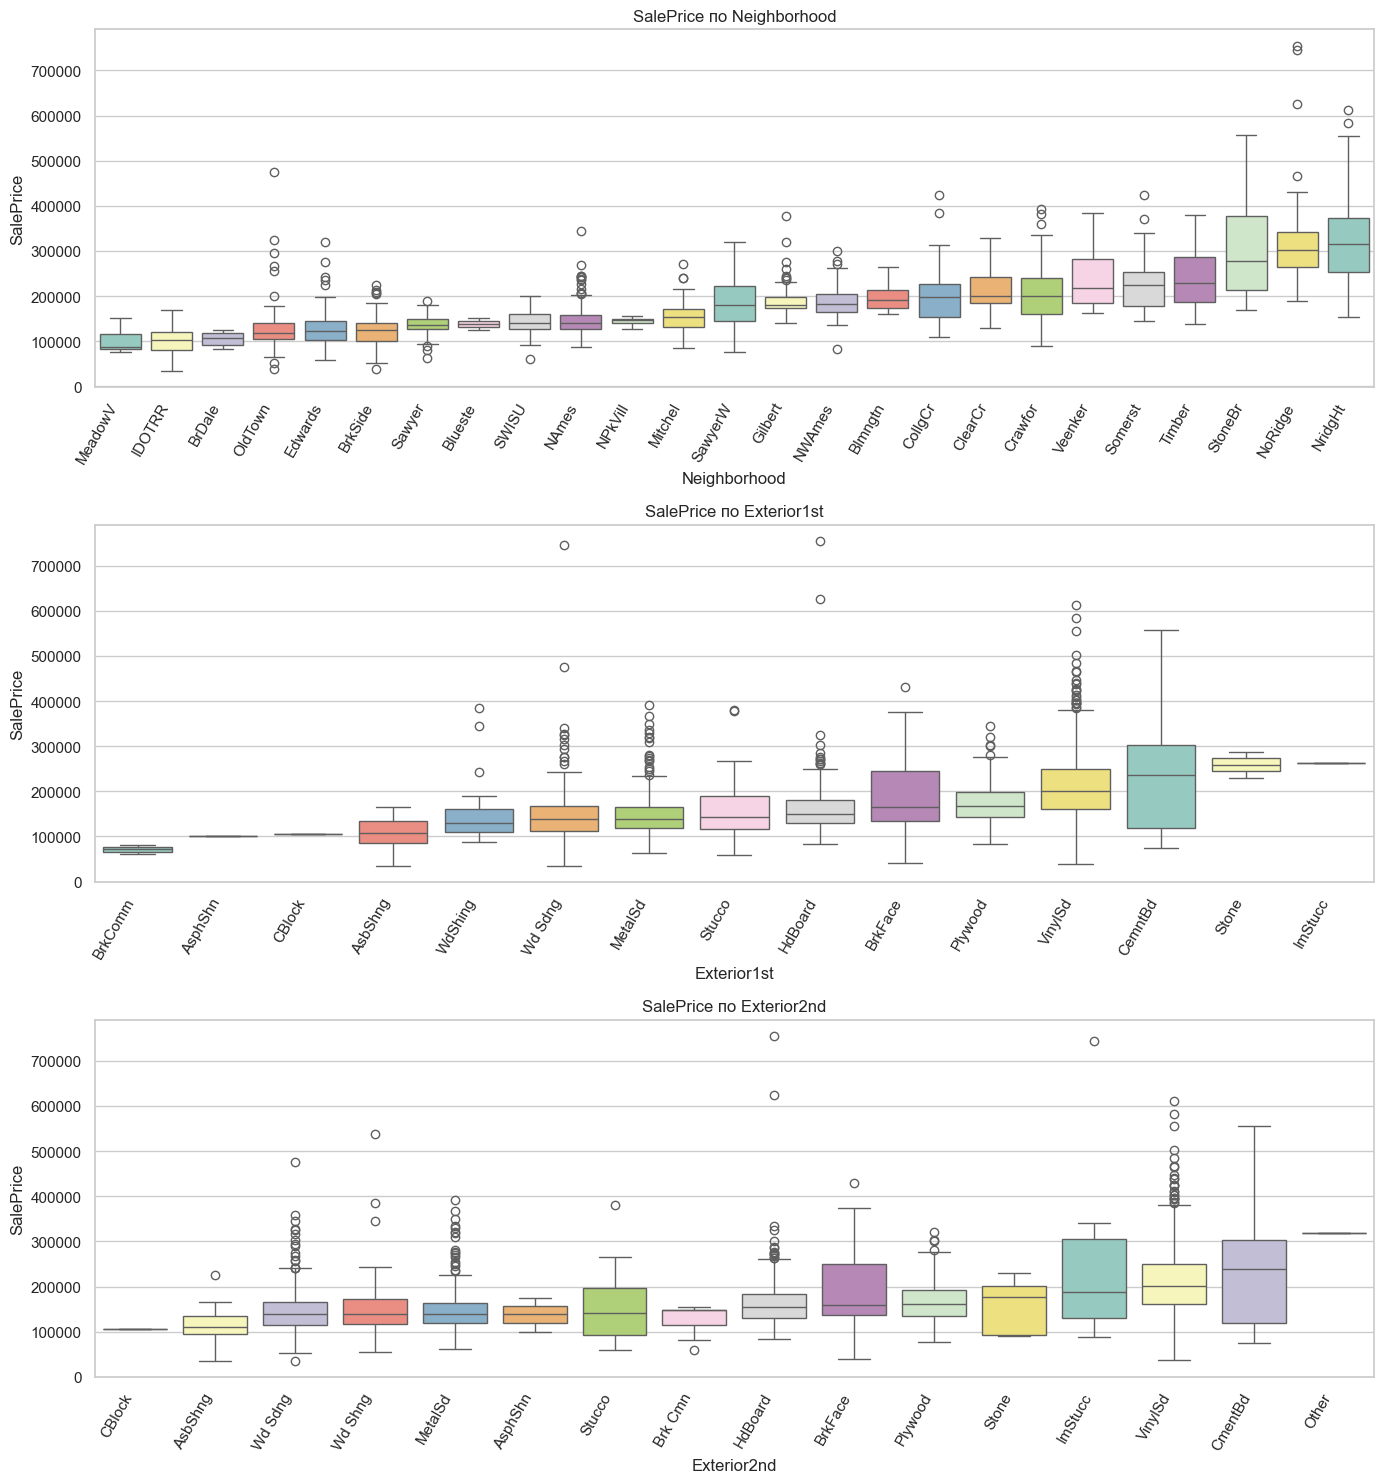

In [38]:
high_card = ["Neighborhood", "Exterior1st", "Exterior2nd"]

fig, axes = plt.subplots(3, 1, figsize=(14, 15))

for ax, col in zip(axes, high_card):
    order = train.groupby(col)["SalePrice"].median().sort_values().index
    sns.boxplot(data=train, x=col, y="SalePrice", order=order, ax=ax, palette="Set3")
    ax.set_title(f"SalePrice по {col}")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=60, ha="right")

plt.tight_layout()
plt.show()

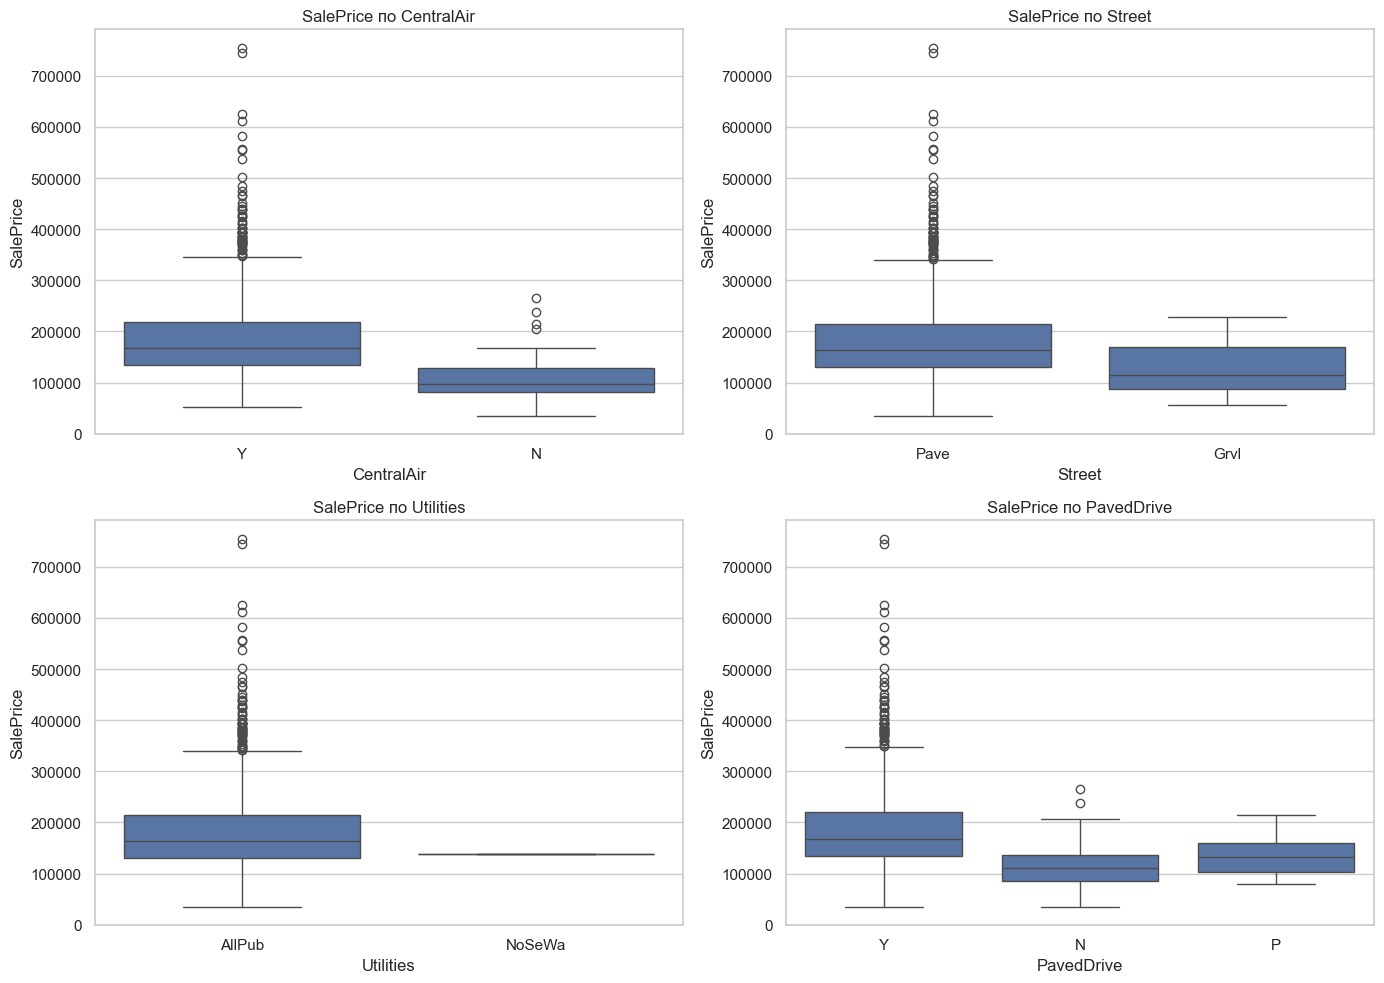

In [39]:
low_card = ["CentralAir", "Street", "Utilities", "PavedDrive"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flat, low_card):
    sns.boxplot(data=train, x=col, y="SalePrice", ax=ax)
    ax.set_title(f"SalePrice по {col}")
plt.tight_layout()
plt.show()

In [40]:
for col in ["Street", "Utilities", "CentralAir", "PavedDrive"]:
    print(f"{col}:")
    print(train[col].value_counts(normalize=True).round(4).to_string())
    print()

Street:
Street
Pave   1.00
Grvl   0.00

Utilities:
Utilities
AllPub   1.00
NoSeWa   0.00

CentralAir:
CentralAir
Y   0.93
N   0.07

PavedDrive:
PavedDrive
Y   0.92
N   0.06
P   0.02



**Выводы по категориальным:**

1. **`Neighborhood`** — самая информативная категориальная фича. Медианные цены различаются в 3–4 раза между районами (`Northridge` vs `IDOTRR`). 25 уникальных значений — после One-Hot добавит 25 колонок.
2. **`Exterior1st` / `Exterior2nd`** — 15/16 значений, тоже полезны.
3. **`CentralAir`** — почти бинарный (Y/N). Дома с кондиционером дороже в среднем.
4. **`Street`** — почти константа (~99.6% `Pave`). Признак с нулевой вариативностью бесполезен, но One-Hot с `handle_unknown="ignore"` его просто проигнорирует.
5. **`Utilities`** — почти константа (`AllPub` ~99.9%). Тоже бесполезен.

**Практический вывод:** One-Hot Encoding даст много разреженных колонок. Для деревьев это не проблема, для KNN и линейных моделей — стоит подумать о feature selection. Но так как основной вклад даёт CatBoost — оставляем как есть.

## 7. Проверка фич из `features.py`

Убедимся, что добавленные признаки (`TotalSF`, `TotalBath`, `TotalPorch`, `Age`, ...) действительно коррелируют с таргетом.


In [41]:
fe = train.copy()

# воспроизводим то, что делает features.py
fe["TotalSF"]      = fe["TotalBsmtSF"] + fe["1stFlrSF"] + fe["2ndFlrSF"]
fe["TotalBath"]    = fe["FullBath"] + 0.5*fe["HalfBath"] + fe["BsmtFullBath"] + 0.5*fe["BsmtHalfBath"]
fe["TotalPorch"]   = fe["OpenPorchSF"] + fe["EnclosedPorch"] + fe["3SsnPorch"] + fe["ScreenPorch"]
fe["Age"]          = (fe["YrSold"] - fe["YearBuilt"]).clip(lower=0)
fe["RemodAge"]     = (fe["YrSold"] - fe["YearRemodAdd"]).clip(lower=0)
fe["HasPool"]      = (fe["PoolArea"] > 0).astype(int)
fe["HasGarage"]    = (fe["GarageArea"] > 0).astype(int)
fe["HasBsmt"]      = (fe["TotalBsmtSF"] > 0).astype(int)
fe["HasFireplace"] = (fe["Fireplaces"] > 0).astype(int)
fe["Has2ndFloor"]  = (fe["2ndFlrSF"] > 0).astype(int)

new_feats = ["TotalSF", "TotalBath", "TotalPorch", "Age", "RemodAge",
             "HasPool", "HasGarage", "HasBsmt", "HasFireplace", "Has2ndFloor"]

corr_new = fe[new_feats + ["SalePrice"]].corrwith(fe["SalePrice"]).drop("SalePrice").sort_values(ascending=False)
print("Корреляции новых фич с SalePrice:")
print(corr_new.round(3))

Корреляции новых фич с SalePrice:
TotalSF         0.78
TotalBath       0.63
HasFireplace    0.47
HasGarage       0.24
TotalPorch      0.20
HasBsmt         0.15
Has2ndFloor     0.14
HasPool         0.09
RemodAge       -0.51
Age            -0.52
dtype: float64


/var/folders/mq/66mrl7xd1pn0sy2xwb1mbmk00000gn/T/ipykernel_47485/4263700374.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=corr_new.values, y=corr_new.index, ax=ax, palette="coolwarm")


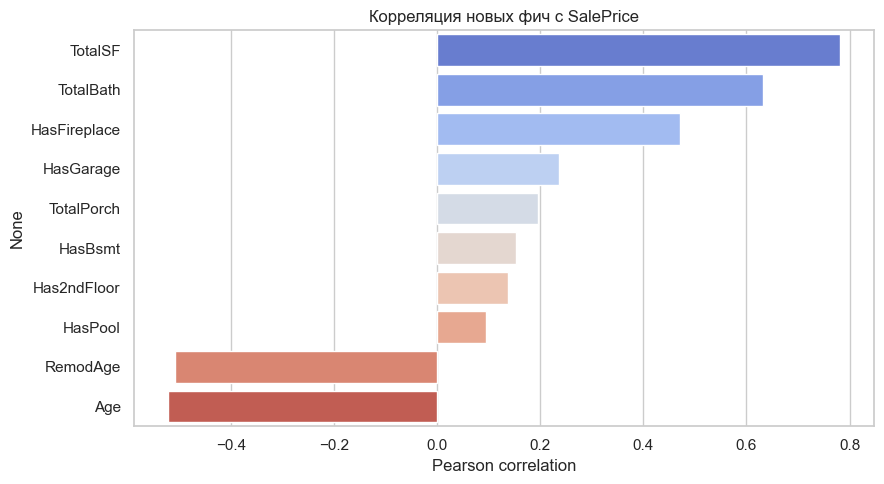

In [42]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=corr_new.values, y=corr_new.index, ax=ax, palette="coolwarm")
ax.set_title("Корреляция новых фич с SalePrice")
ax.set_xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

In [43]:
compare = pd.DataFrame({
    "feature": ["TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "GrLivArea", "TotalSF"],
    "corr": [
        train["TotalBsmtSF"].corr(train["SalePrice"]),
        train["1stFlrSF"].corr(train["SalePrice"]),
        train["2ndFlrSF"].corr(train["SalePrice"]),
        train["GrLivArea"].corr(train["SalePrice"]),
        fe["TotalSF"].corr(fe["SalePrice"]),
    ],
}).sort_values("corr", ascending=False)

print(compare.round(4).to_string(index=False))

    feature  corr
    TotalSF  0.78
  GrLivArea  0.71
TotalBsmtSF  0.61
   1stFlrSF  0.61
   2ndFlrSF  0.32


**Вывод:** Новые фичи подтверждают свою полезность:

- **`TotalSF`** коррелирует с таргетом **сильнее**, чем любая из исходных площадей (`GrLivArea`, `TotalBsmtSF`, `1stFlrSF`). Это ожидаемо: мы объединили три источника в один сигнал.
- **`TotalBath`** — суммарный комфорт. Корреляция ~0.63, сильнее, чем `FullBath` в отдельности.
- **`Age` / `RemodAge`** — обратная корреляция (старые дома дешевле). После ремонта — дороже.
- **`HasGarage`, `HasBsmt`, `HasFireplace`** — умеренная корреляция, но ценны как нелинейные сигналы: «есть / нет» часто важнее, чем количественная величина.
- **`HasPool`** — почти нулевая корреляция (бассейн только у ~0.5% домов). Оставляем, но вклад минимальный.

Эти фичи в `features.py` — не «для галочки», а реально усиливают сигнал. Особенно `TotalSF`.


## 8. Мультиколлинеарность

Проверим, насколько сильно числовые признаки коррелируют друг с другом. Для CatBoost/XGBoost это не критично, но для Ridge и KNN — важно.

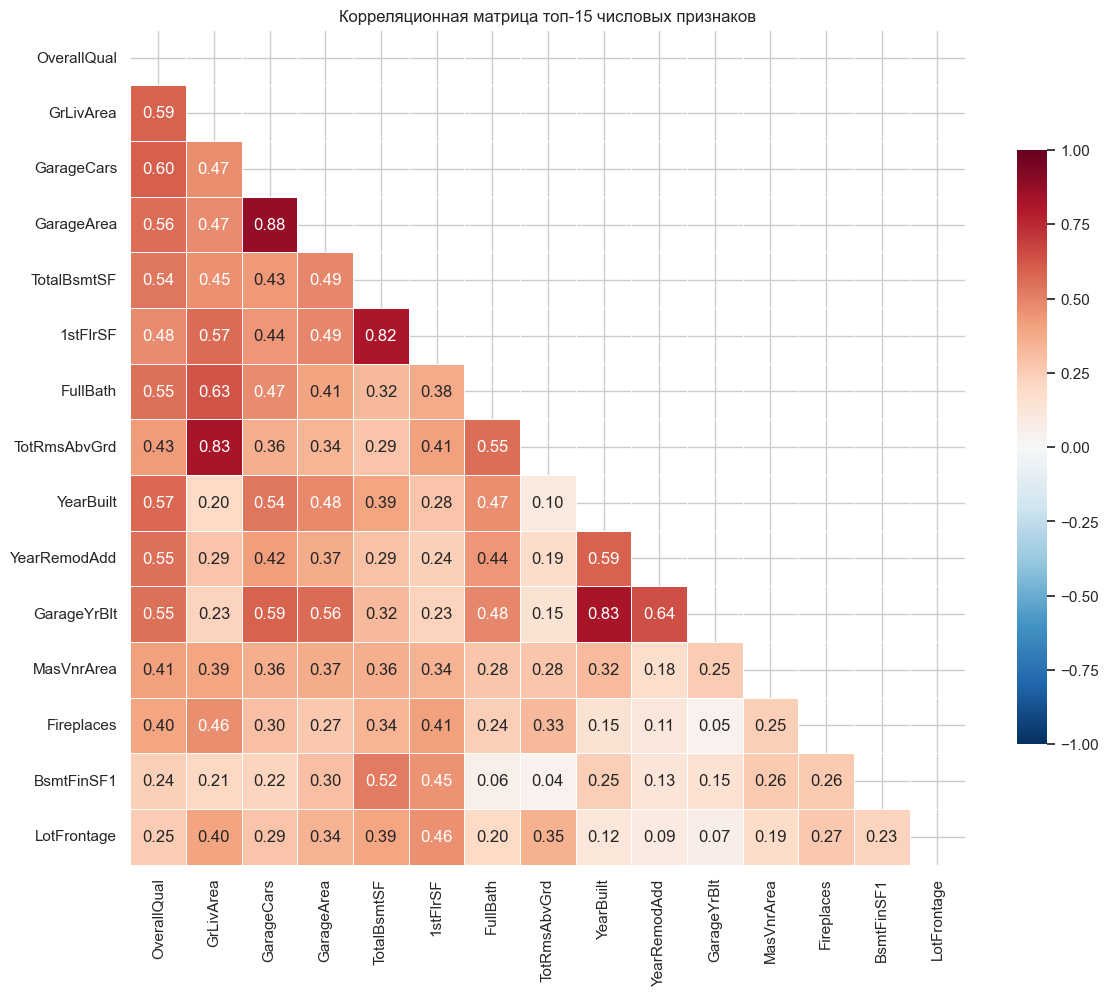

In [44]:
top_num = corr_with_target.drop("SalePrice").head(15).index.tolist()
corr_matrix = train[top_num].corr()

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.5, ax=ax, cbar_kws={"shrink": 0.7},
)
ax.set_title("Корреляционная матрица топ-15 числовых признаков")
plt.tight_layout()
plt.show()

In [45]:
corr_pairs = (
    corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .sort_values(ascending=False)
)

print("Топ-10 пар с самой высокой корреляцией:")
print(corr_pairs.head(10).round(3).to_string())

Топ-10 пар с самой высокой корреляцией:
GarageCars    GarageArea     0.88
YearBuilt     GarageYrBlt    0.83
GrLivArea     TotRmsAbvGrd   0.82
TotalBsmtSF   1stFlrSF       0.82
YearRemodAdd  GarageYrBlt    0.64
GrLivArea     FullBath       0.63
OverallQual   GarageCars     0.60
              GrLivArea      0.59
YearBuilt     YearRemodAdd   0.59
GarageCars    GarageYrBlt    0.59


**Вывод:** Видны **сильные корреляции** между признаками:

- `GarageCars` ↔ `GarageArea` (~0.88) — почти дубликаты.
- `GrLivArea` ↔ `TotRmsAbvGrd` (~0.83) — большая площадь = больше комнат.
- `TotalBsmtSF` ↔ `1stFlrSF` (~0.82) — подвал обычно под первым этажом.
- `YearBuilt` ↔ `GarageYrBlt` (~0.83) — гараж строили вместе с домом.

**Что это значит:**

- **Для Ridge и KNN** мультиколлинеарность создаёт проблему: коэффициенты становятся нестабильными, расстояния в KNN искажаются. Помогает L2-регуляризация — `Ridge(alpha=1.0)` прижимает веса коррелирующих признаков.
- **Для CatBoost/XGBoost** это **не проблема**: деревья выбирают один из коррелирующих признаков и работают с ним.

**Практический вывод:** в пайплайне `standart`-препроцессинг использует Ridge с `alpha=1.0` — это разумная защита от мультиколлинеарности. Для CatBoost и XGBoost никаких правок не нужно.

## 9. Итоговые выводы EDA

Всё, что выше, легло в архитектуру пайплайна `final_houses`.

### Что с таргетом
- `SalePrice` скошен (skew ≈ 1.88) → **обучаем на `log1p(SalePrice)`**, метрика в log-пространстве.
- Флаг `data.log_target: true`.
- Обратное преобразование `expm1` — только при формировании submission.

### Что с пропусками
- Категориальные NaN → **`"None"`** (а не мода), потому что NaN значит «отсутствует объект».
- Числовые NaN → **медиана** (устойчива к выбросам).

### Что с категориальными
- **One-Hot Encoding** с `handle_unknown="ignore"`.
- Для CatBoost — **автоопределение** категориальных через `select_dtypes(include=["object"])`.
- Признаки с нулевой вариативностью (`Street`, `Utilities`) безвредны — One-Hot их проигнорирует.

### Что с числовыми
- **`log1p`-преобразование** перед масштабированием (в `standart`-пайплайне).
- **`StandardScaler`** — обязателен для Ridge и KNN.
- Для деревьев — без масштабирования, деревья инвариантны.

### Что с фичами
- `TotalSF`, `TotalBath`, `TotalPorch`, `Age`, `RemodAge` — **подтверждённо полезны**.
- Бинарные `Has*` — слабая линейная корреляция, но нелинейный сигнал («есть/нет»).
- `clip(lower=0)` для `Age`/`RemodAge` — критичен, иначе `log1p` упадёт на отрицательных значениях.

### Что с выбросами
- Два дома с `GrLivArea > 4000` и ценой < $300k — знаменитые выбросы.
- В пайплайне **не удаляем** — оставляем как есть. После `log1p` их влияние сглаживается.

### Что с моделями
- **CatBoost** — лучшая одиночная модель (RMSE ≈ 0.124).
- **XGBoost** и **Ridge** — хорошие вторые номера.
- **KNN** и **DecisionTree** — слабые, оставлены для полноты эксперимента.
- **Ансамбль voting / weighted_average** — 0.1236, чуть лучше CatBoost в одиночку.

### Что с кросс-валидацией
- **KFold** (не Stratified) — в регрессии классов нет.
- 5 фолдов — компромисс между скоростью и стабильностью оценки.
- Метрика — RMSE в log-пространстве.

---

## Сводная таблица решений

| Наблюдение | Решение | Где |
|---|---|---|
| `SalePrice` skew ≈ 1.88 | `log1p` таргета | `main.py`, `config` |
| Категориальные NaN = «нет» | `fill_value="None"` | `preprocessing.py` |
| Числовые NaN | `median` | `preprocessing.py` |
| Числа скошены | `log1p` в `standart` | `preprocessing.py` |
| One-Hot разрежен | `handle_unknown="ignore"` | `preprocessing.py` |
| CatBoost cat_features | Авто через `select_dtypes` | `preprocessing.py` |
| Мультиколлинеарность | `Ridge(alpha=1.0)` | `config.yaml` |
| Два выброса | Не удаляем | — |
| `TotalSF` > отдельных площадей | Feature engineering | `features.py` |
| Отрицательный `Age` | `clip(lower=0)` | `features.py` |
| Регрессия | `KFold` вместо `Stratified` | `validation.py` |
| RMSE: меньше = лучше | `minimize`, `reverse=False` | `optuna`, `main` |

---

## Что можно улучшить (за пределами текущего пайплайна)

1. **Удалить 2 выброса** `GrLivArea > 4000 & SalePrice < 300k` — обычно даёт -1–3% RMSE. Но не обязательно: после `log1p` эффект мал.
2. **Optuna-тюнинг CatBoost** — `mode: tuning`, `n_trials: 40`. Ожидаемо -2–4% RMSE.
3. **Blending с оптимизацией весов** через Optuna вместо ручных 0.15/0.50/0.35.
4. **Добавить LightGBM** — по скорости и качеству близок к CatBoost, часто даёт +0.001–0.002 в ансамбле.
5. **Ordinal encoding для оценок качества** (`ExterQual`, `KitchenQual`, ...) вместо One-Hot — сохраняет порядок Po < Fa < TA < Gd < Ex.
6. **Target encoding для `Neighborhood`** — иногда лучше One-Hot на высококардинальных признаках.